<h2 style="color: MediumPurple; font-family:; text-align:center;font-size:35px">
  Tarea 2: Modelo de ML para EXOPLANETAS
</h2>
<h1 style="color: MediumPurple; font-size:13.5px;"> Students: </h1>Ornella Cañellas Arredondo and Valentina Cortés Flores
<h1 style="color: MediumPurple; font-size:13.5px;"> Rol:  </h1> 202387002-1 ;  202287510-0
<h1 style="color: MediumPurple; font-size:13.5px;"> Professor and Assistant: </h1> Pía Amigo and Joseph Dabre

<h2 style="color:fuchsia; font-family:; text-align:center;font-size:23px">
  (1) ❁Predicción ❁
</h2>

- **Target:** `P_HABZONE_OPT` (1 = el exoplaneta está en zona de habitabilidad óptima, 0 = no, datos binarios).
- **Features:** `P_TEMP_SURF`, `P_DISTANCE`, `P_RADIUS`, `P_MASS`.
- **Tipo de problema:** Clasificación binaria, porque se quiere justamente clasificar cuáles exoplanetas serían habitables o no.  
- **¿Por qué los datos podrían tener información útil?** En la Tarea 1 vimos que la fracción de exoplanetas en zona
  habitable óptima se concentra en temperaturas de 200-300 K y distancias de 0.4 a 5 UA, y que `P_TEMP_SURF` era la
  variable más correlacionada con el target.
- **Posibles dificultades:** Como se observó, existen datos faltantes, además de variados outliers, además de posibles sesgos por alguna variable.
    (Por ejemplo: datos faltantes, clases desbalanceadas, pocas observaciones, outliers, features muy relacionadas entre sí o posibles sesgos en la muestra.)

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("white")

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, f1_score, recall_score, precision_score,
                             classification_report, ConfusionMatrixDisplay)

EXO_set = pd.read_csv("hwc.csv")
target = "P_HABZONE_OPT"
print("Exoplanetas en el dataset:", len(EXO_set))
print(EXO_set.loc[EXO_set[target] == 1, "P_TYPE_TEMP"].value_counts()) #1 habitable

Exoplanetas en el dataset: 5599
P_TYPE_TEMP
Warm    264
Name: count, dtype: int64


In [4]:
import matplotlib
import matplotlib.pyplot as plt
pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_colwidth', 100)
font = {'size'   : 16}
matplotlib.rc('font', **font)
matplotlib.rc('xtick', labelsize=14)
matplotlib.rc('ytick', labelsize=14)
matplotlib.rcParams.update({'figure.autolayout': False})
matplotlib.rcParams['figure.dpi'] = 300

Todos los exoplanetas potencialmente habitables o en su gran mayoría son de clase `Warm`: usar `P_TYPE_TEMP` como feature sería muy evidente para el
modelo, por eso la excluimos.

<h2 style="color:fuchsia; font-family:; text-align:center;font-size:23px">
  (2) ❁ Selección de algoritmo de ML: SVM con kernel RBF ❁
</h2>

La selección del algoritmo es SVM con kernel gaussiano (o también RBF) que ayuda a establecer una búsqueda de parámetros para los cuales no existe relación lineal. De esta forma busca la frontera que separa las clases con el mayor margen posible. Con el kernel gaussiano esa frontera
puede ser curva, lo que calza con nuestro problema: la zona óptima habitable puede ser considerada como en un rango (ni muy frío ni muy caliente,
ni muy cerca ni muy lejos), y una frontera recta o relación lineal no podría encerrar puede encerrar "una ventana" o un rango específico, sino que es muy variado.
El kernel usa distancias entre puntos, así que es sensible a la escala de las variables: hay que estandarizar las escalas, osea escalar. Al tener en cuenta el hiperparámetro `C`, que controla cuánto se penalizan los errores de entrenamiento, tendremos dos casos`C` bajo = margen ancho que tolera
   errores (modelo simple, tiende al subajuste); `C` alto = intenta clasificar bien todo (frontera compleja,
   tiende al sobreajuste y a una "perfección imperfecta").

<h2 style="color:fuchsia; font-family:; text-align:center;font-size:23px">
  (3) ❁ Train y Test set ❁
</h2>

In [5]:
features = ["P_TEMP_SURF", "P_DISTANCE", "P_RADIUS", "P_MASS"]

df = EXO_set[features + [target]].dropna().copy()
n_pos_total = int(EXO_set[target].sum())
n_pos_usados = int(df[target].sum())
print(f"Exoplanetas exitentes en los datos: {len(df)} de {len(EXO_set)}")
print(f"Habitables en el targett: {n_pos_total} | habitables que quedan para el modelo: {n_pos_usados}")

sin_temp = EXO_set[(EXO_set[target] == 1) & (EXO_set["P_TEMP_SURF"].isna())]
print(f"\nHabitables descartados por no tener temperatura: {len(sin_temp)}")
print(sin_temp["P_DETECTION"].value_counts())

Exoplanetas exitentes en los datos: 2441 de 5599
Habitables en el targett: 264 | habitables que quedan para el modelo: 70

Habitables descartados por no tener temperatura: 194
P_DETECTION
Radial Velocity              146
Transit                       45
Transit Timing Variations      2
Eclipse Timing Variations      1
Name: count, dtype: int64


Como se observa para `P_TEMP_SURF` tiene ~56% de datos faltantes y en la Tarea 1 decidimos no imputarla, así que eliminamos
las filas incompletas. Esta decisión tiene un costo importante, ya que, se pierde la mayoría de los exoplanetas habitables y la mayoría de los que se pierden fueron detectados por velocidad radial, que casi nunca entrega
temperatura. El modelo se entrena entonces con una muestra sesgada, es decir, desbalanceada.

Además, como `P_DISTANCE`, `P_MASS` y `P_RADIUS` abarcan varios órdenes de magnitud y tienen
outliers muy extremos, podemos aplicar `log10`, dado que no genera data leakage.

Luego, para los set de train y test, tomamos en cuenta un 70% y 30%, estratificada (`stratify=y`) y con semilla fija para reproducibilidad. Usamos 30% para test porque hay
muy pocos habitables y queremos que el test tenga una cantidad razonable de ellos.

In [7]:
X = df[features].copy()
for col in ["P_DISTANCE", "P_MASS", "P_RADIUS"]:
    X[col] = np.log10(X[col])
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)
print(f"Train: {len(X_train)} exoplanetas ({int(y_train.sum())} habitables)")
print(f"Test:  {len(X_test)} exoplanetas ({int(y_test.sum())} habitables)")

def crear_modelo(C):
    return Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(kernel="rbf", C=C, gamma="scale", random_state=42)),
    ])

# Modelo original: valores por defecto de sklearn (C = 1)
modelo = crear_modelo(C=1).fit(X_train, y_train)

Train: 1708 exoplanetas (49 habitables)
Test:  733 exoplanetas (21 habitables)


<h2 style="color:fuchsia; font-family:; text-align:center;font-size:23px">
  (4) ❁ Evaluación con métrica ❁
</h2>

**Métrica principal: F1-score de la clase habitable.** Solo ~3% de los exoplanetas son habitables, así que un modelo que
respondiera siempre "no habitable" tendría un accuracy cercano a 97% sin servir para nada. El F1 combina *precision*
(prediccion d ehabitables, ¿cuántos lo son?) y *recall* (de los habitables reales)

In [8]:
def evaluar(m, Xa, ya):
    p = m.predict(Xa)
    return {"accuracy": accuracy_score(ya, p), "precision": precision_score(ya, p, zero_division=0),
            "recall": recall_score(ya, p), "f1": f1_score(ya, p)}

pd.DataFrame({"train": evaluar(modelo, X_train, y_train),
              "test": evaluar(modelo, X_test, y_test)}).round(3)

,train,test
accuracy,0.971,0.971
precision,0.000,0.000
recall,0.000,0.000
f1,0.000,0.000


              precision    recall  f1-score   support

           0       0.97      1.00      0.99       712
           1       0.00      0.00      0.00        21

    accuracy                           0.97       733
   macro avg       0.49      0.50      0.49       733
weighted avg       0.94      0.97      0.96       733



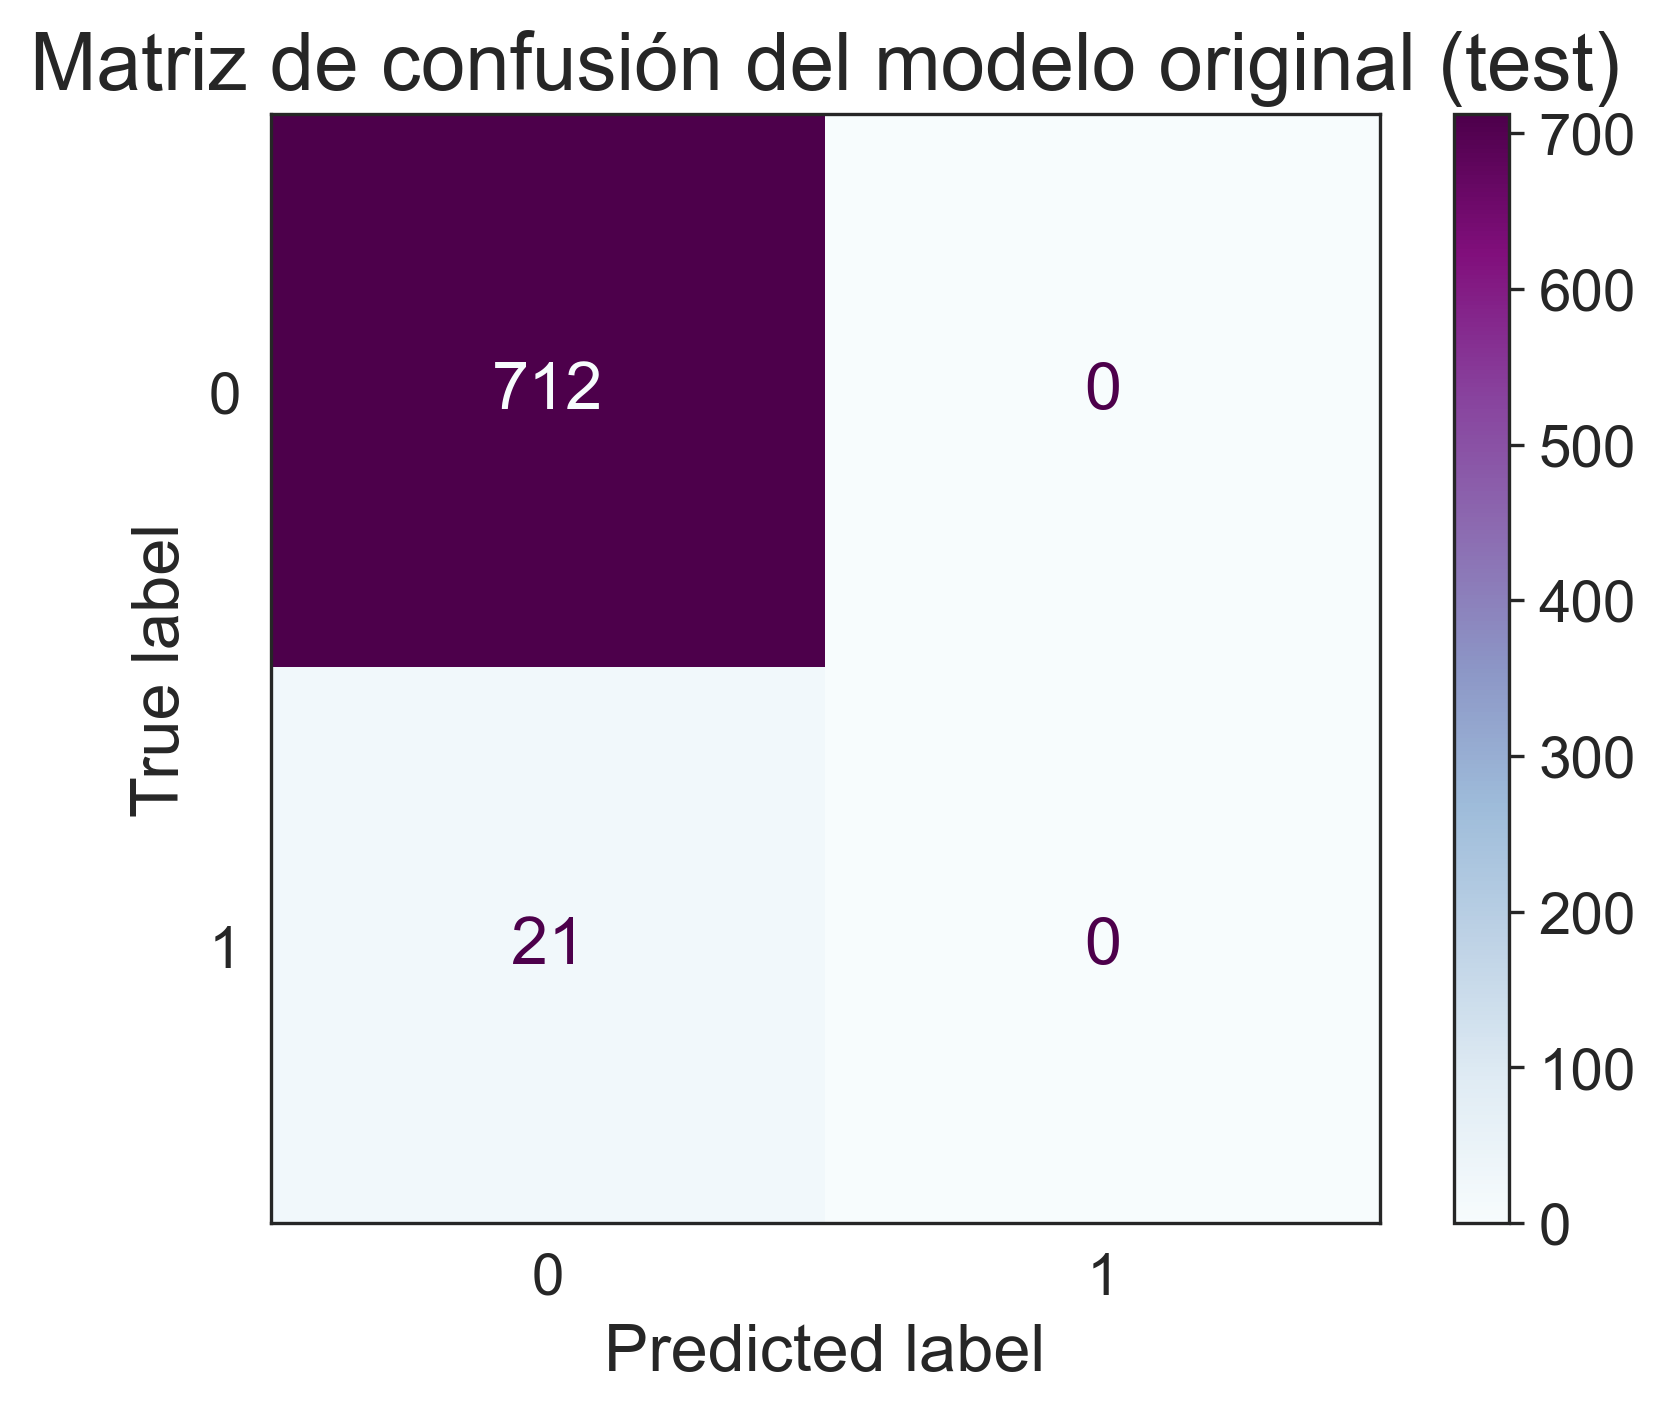

In [9]:
y_pred = modelo.predict(X_test)
print(classification_report(y_test, y_pred, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="BuPu")
plt.title("Matriz de confusión del modelo original (test)")
plt.show()

Como se puede ver, utilizando el modelo original con C=1, se tiene un accuracy de alrededor 97% tanto en train como en test, pero su F1,
precision y recall son 0; lo que predice que ningún exoplaneta resulta en una zona potencialmente habitable (los 21 habitables del test son falsos
negativos). Como la muestra está desbalanceada, estaría mostrando que hay 97% de exoplanetas no localizados en zona potencialmente habitable. Como el desempeño es igual de malo en train que en test, sería un subajuste, el modelo ni
siquiera aprendió el train. Este resultado muestra por qué el accuracy no sirve como métrica en este problema.

<h2 style="color:fuchsia; font-family:; text-align:center;font-size:23px">
  (5) ❁ Modificando 1 aspecto: el hiperparámetro `C` ❁
</h2>

<h2 style="color:lightblue; font-family:; text-align:left;font-size:17px">
 Predicción: ¿qué cambio esperamos observar en el desempeño y por qué?
</h2>
Ahora utilizando la misma proporción de datos, pero cambiando el valor de C a 0.01, esperariamos un subajuste, donde el SVM tolera demasiados errores
y la frontera queda muy suave, por lo que le costará capturar un rango de zona óptima de habitabilidad exacto y el F1 será bajo tanto en
train como en test. Por otra parte, al aumentar el valor C, el F1 de train y de test debería subir. Con C muy alto (1000) esperamos que el F1
de train siga subiendo o se estanque, mientras el de test se estanca o baja, porque la frontera se ajusta a puntos
individuales generando un sobreajuste, lo que debería verse como una brecha creciente entre train y test.
Entonces la propuesta es solo cambiar C, mientras que los features, escalado, split, kernel y `gamma` se mantienen.

<h2 style="color:lightblue; font-family:; text-align:left;font-size:17px">
 Experimento: modificamos solo C y comparamos con el modelo original (mismo split train/test)
</h2>

In [10]:
filas = []
for C in [0.01, 0.1, 1, 10, 100, 1000]:
    m = crear_modelo(C).fit(X_train, y_train)
    tr, te = evaluar(m, X_train, y_train), evaluar(m, X_test, y_test)
    filas.append({"C": C, "F1 train": tr["f1"], "F1 test": te["f1"],
                  "precision test": te["precision"], "recall test": te["recall"],
                  "accuracy train": tr["accuracy"], "accuracy test": te["accuracy"]})
tabla = pd.DataFrame(filas).round(3)
tabla

,C,F1 train,F1 test,precision test,recall test,accuracy train,accuracy test
0,0.01,0.000,0.000,0.000,0.000,0.971,0.971
1,0.10,0.000,0.000,0.000,0.000,0.971,0.971
2,1.00,0.000,0.000,0.000,0.000,0.971,0.971
3,10.00,0.773,0.649,0.750,0.571,0.988,0.982
4,100.00,0.845,0.632,0.706,0.571,0.991,0.981
5,1000.00,0.958,0.800,0.842,0.762,0.998,0.989


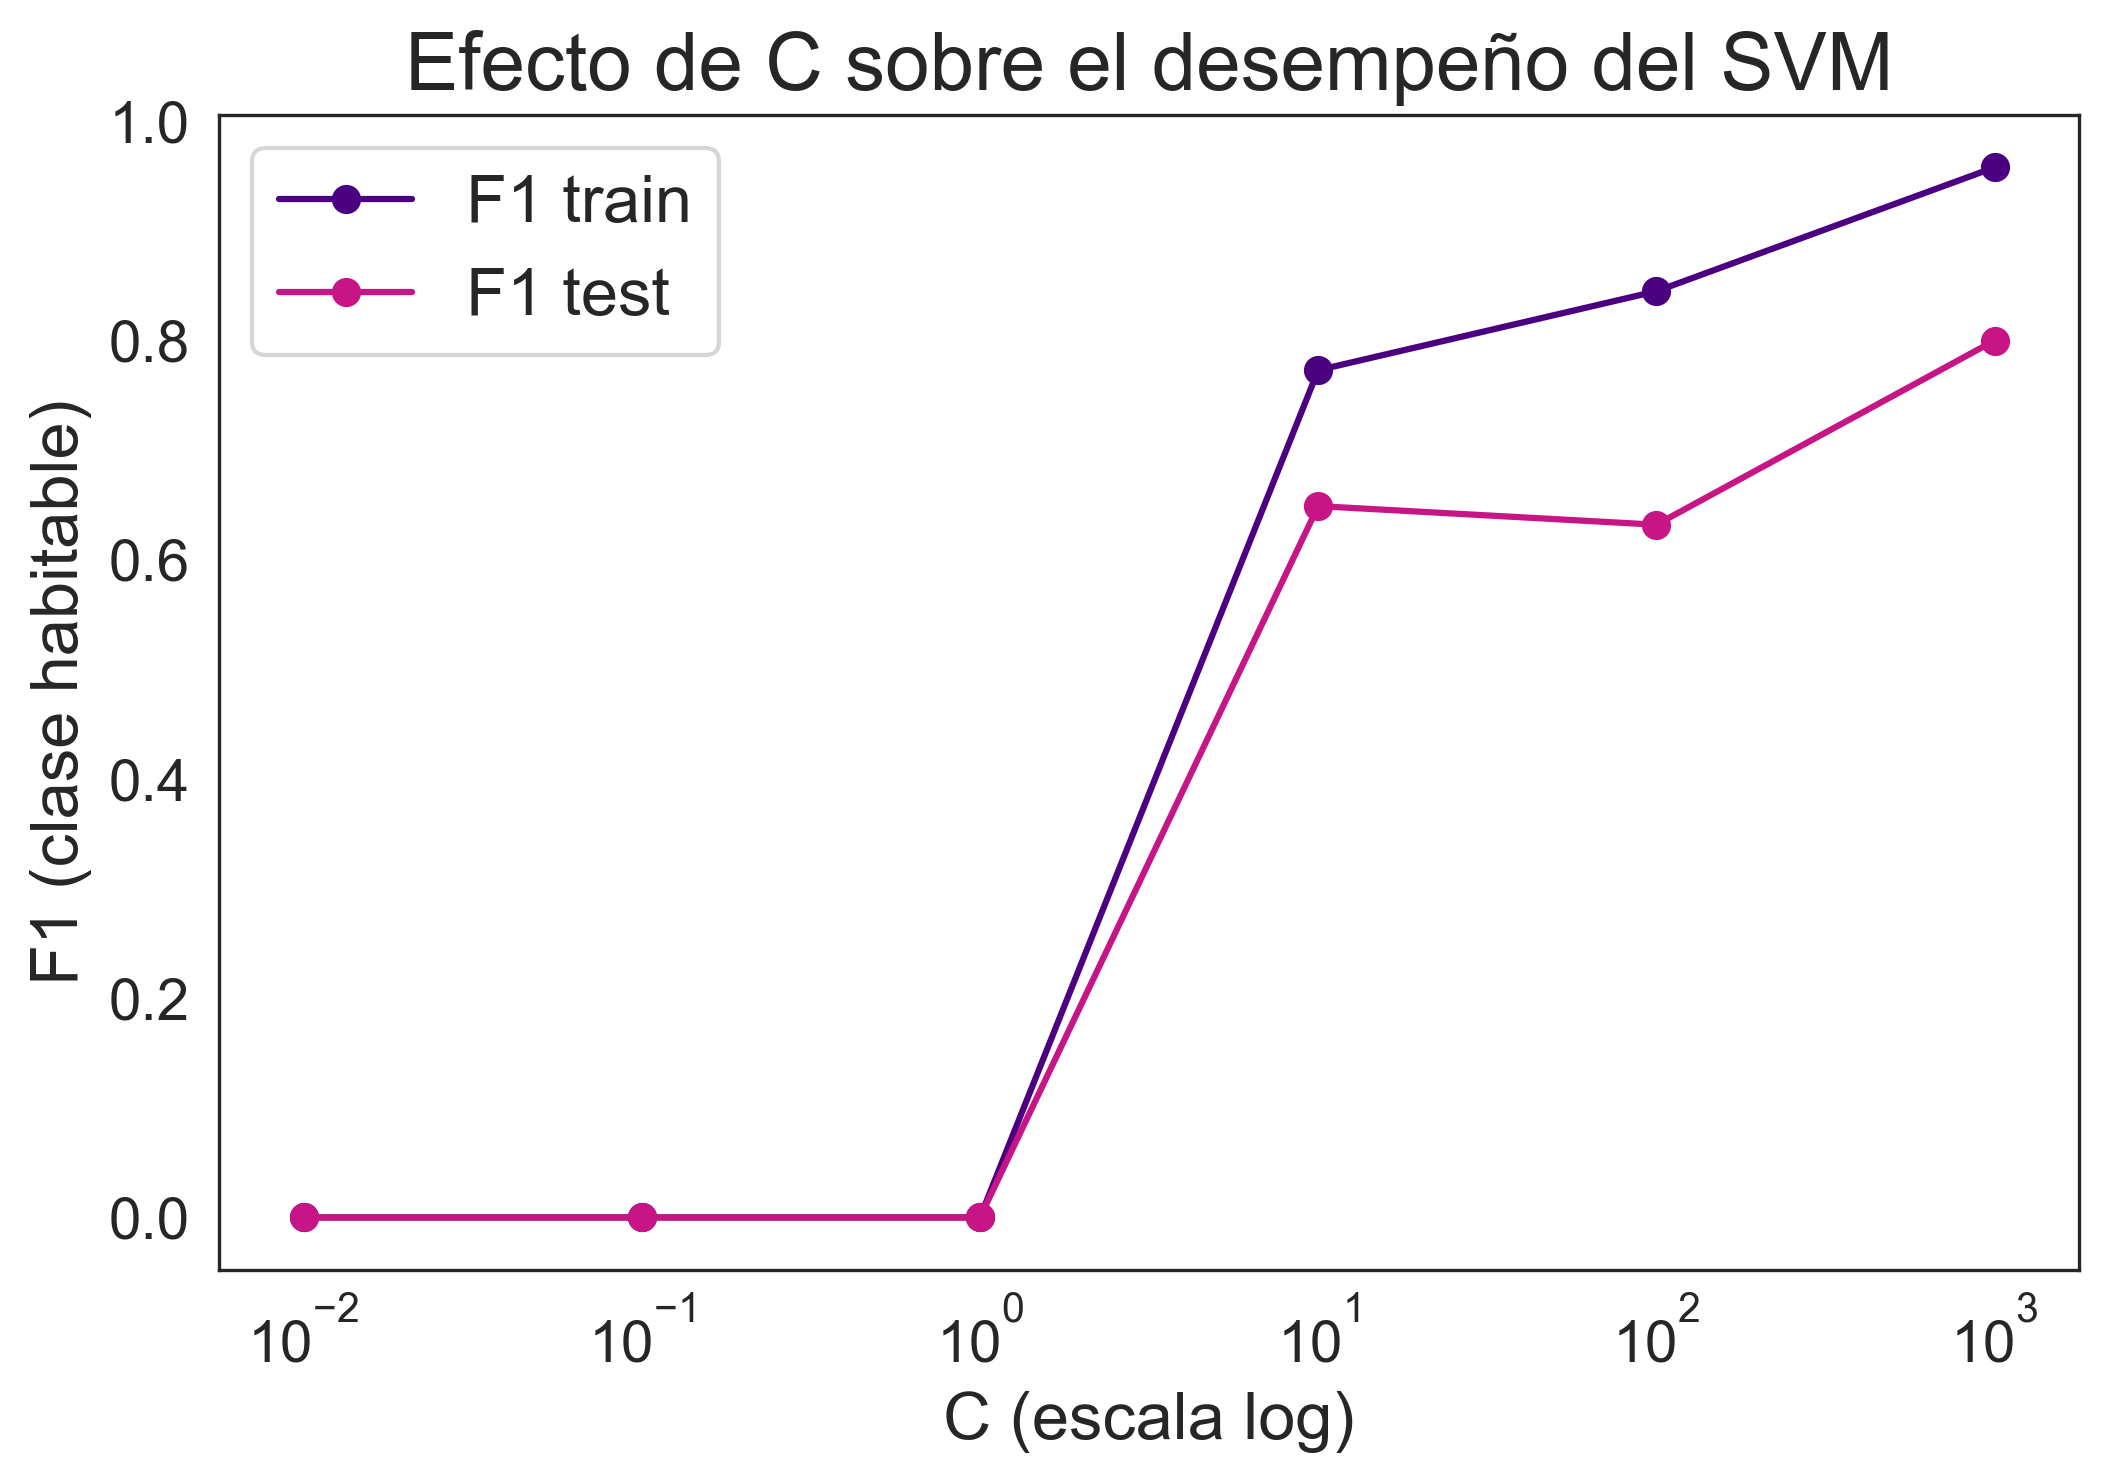

In [11]:
plt.figure(figsize=(8, 5))
plt.plot(tabla["C"], tabla["F1 train"], marker="o", color="indigo", label="F1 train")
plt.plot(tabla["C"], tabla["F1 test"], marker="o", color="mediumvioletred", label="F1 test")
plt.xscale("log")
plt.xlabel("C (escala log)")
plt.ylabel("F1 (clase habitable)")
plt.title("Efecto de C sobre el desempeño del SVM")
plt.legend()
plt.show()

<h2 style="color:lightblue; font-family:; text-align:left;font-size:17px">
 Interpretación: ¿se cumplió la predicción? ¿qué concluimos sobre el modelo?
</h2>
La predicción se cumplió en parte.

- Con un valor de `C` ≤ 1 hay subajuste total (F1 = 0 en train y en test). Al llegar a `C = 10` el modelo por fin
  detecta habitables (F1 train 0.77, test 0.65) y el F1 de train sigue subiendo con `C` hasta 0.96, es decir, el modelo
  se ajusta casi perfecto a los pocos habitables de train. La brecha entre train y test es de 0.12 con `C = 10`,
  0.21 con `C = 100` y 0.16 con `C = 1000`.
- Por otra parte no se cumplió lo que esperábamos acerca de que el F1 de test se estancara o bajara con `C` alto, pero con `C = 1000` fue el más
  alto (0.80).

El test tiene solo 21 habitables. Que `C = 10` y `C = 100` den F1 de test casi iguales (0.65 y 0.63), o que `C = 1000` llegue a 0.80, esta dentro
del rango que esperaríamos por un tamaño de test tan pequeño (21). Lo que sí podemos concluir es que: el modelo es muy
sensible a `C`, con clases tan desbalanceadas necesita un `C` alto para dejar de responder siempre "no habitable", y a `C` alto el modelo casi memoriza el train, lo que es un "aviso" de sobreajuste.

<h2 style="color:fuchsia; font-family:; text-align:center;font-size:23px">
  (6) ❁ Cómo funciona el modelo ❁
</h2>

<h2 style="color:lightblue; font-family:; text-align:left;font-size:17px">
 ¿Qué tan bien generaliza el modelo?
</h2>

- **Modelo original (`C = 1`):** F1 = 0 en train y en test → **subajuste**, no generaliza porque no aprendió.
- **Con `C` alto (10, 100, 1000):** el F1 de train (0.77, 0.85, 0.96) es mayor que el de test (0.65, 0.63, 0.80), con
  brechas de 0.12 a 0.21. Hay indicios moderados de sobreajuste, que crecen en `C` = 100 y `C` = 1000 donde el
  modelo casi memoriza el train.
- Como se menciono, con solo 21 habitables en test, estos números son inestables por parte del desbalanceo de clases, y no podemos afirmar cuál `C` es mejor.

<h2 style="color:lightblue; font-family:; text-align:left;font-size:17px">
 ¿Dónde falla el modelo?
</h2>

Al analizar los errores del modelo con `C = 10`, el modelo falla con el primer valor donde el modelo deja de predecir siempre "zona no potencialmente habitable".

In [13]:
modelo_C10 = crear_modelo(10).fit(X_train, y_train)
pred = modelo_C10.predict(X_test)
mask = pred != y_test.values

errores = df.loc[X_test.index[mask], features].copy()
errores.insert(0, "P_NAME", EXO_set.loc[errores.index, "P_NAME"])
errores["real"] = y_test[mask]
errores["pred"] = pred[mask]

print(f"Errores en test: {len(errores)} de {len(y_test)}")
print(f"Falsos negativos: {int((errores['real'] == 1).sum())}")
print(f"Falsos positivos: {int((errores['real'] == 0).sum())}")
errores.sort_values("P_TEMP_SURF").round(3).reset_index(drop=True)

Errores en test: 13 de 733
Falsos negativos: 9
Falsos positivos: 4


,P_NAME,P_TEMP_SURF,P_DISTANCE,P_RADIUS,P_MASS,real,pred
0,Teegarden's Star d,167.670,0.079,0.954,0.820,0,1
1,Kapteyn c,183.163,0.319,2.540,7.000,0,1
2,Kepler-441 b,196.252,0.643,1.640,3.330,0,1
3,Kepler-62 f,229.807,0.718,1.410,35.000,1,0
4,HD 40307 g,255.720,0.625,2.560,7.100,1,0
5,TRAPPIST-1 d,295.674,0.022,0.788,0.388,1,0
6,GJ 367 d,296.509,0.161,2.330,6.030,1,0
7,Kepler-62 e,297.997,0.427,1.610,36.000,1,0
8,K2-332 b,298.986,0.086,2.200,5.480,1,0
9,GJ 163 c,303.746,0.126,2.500,6.800,1,0


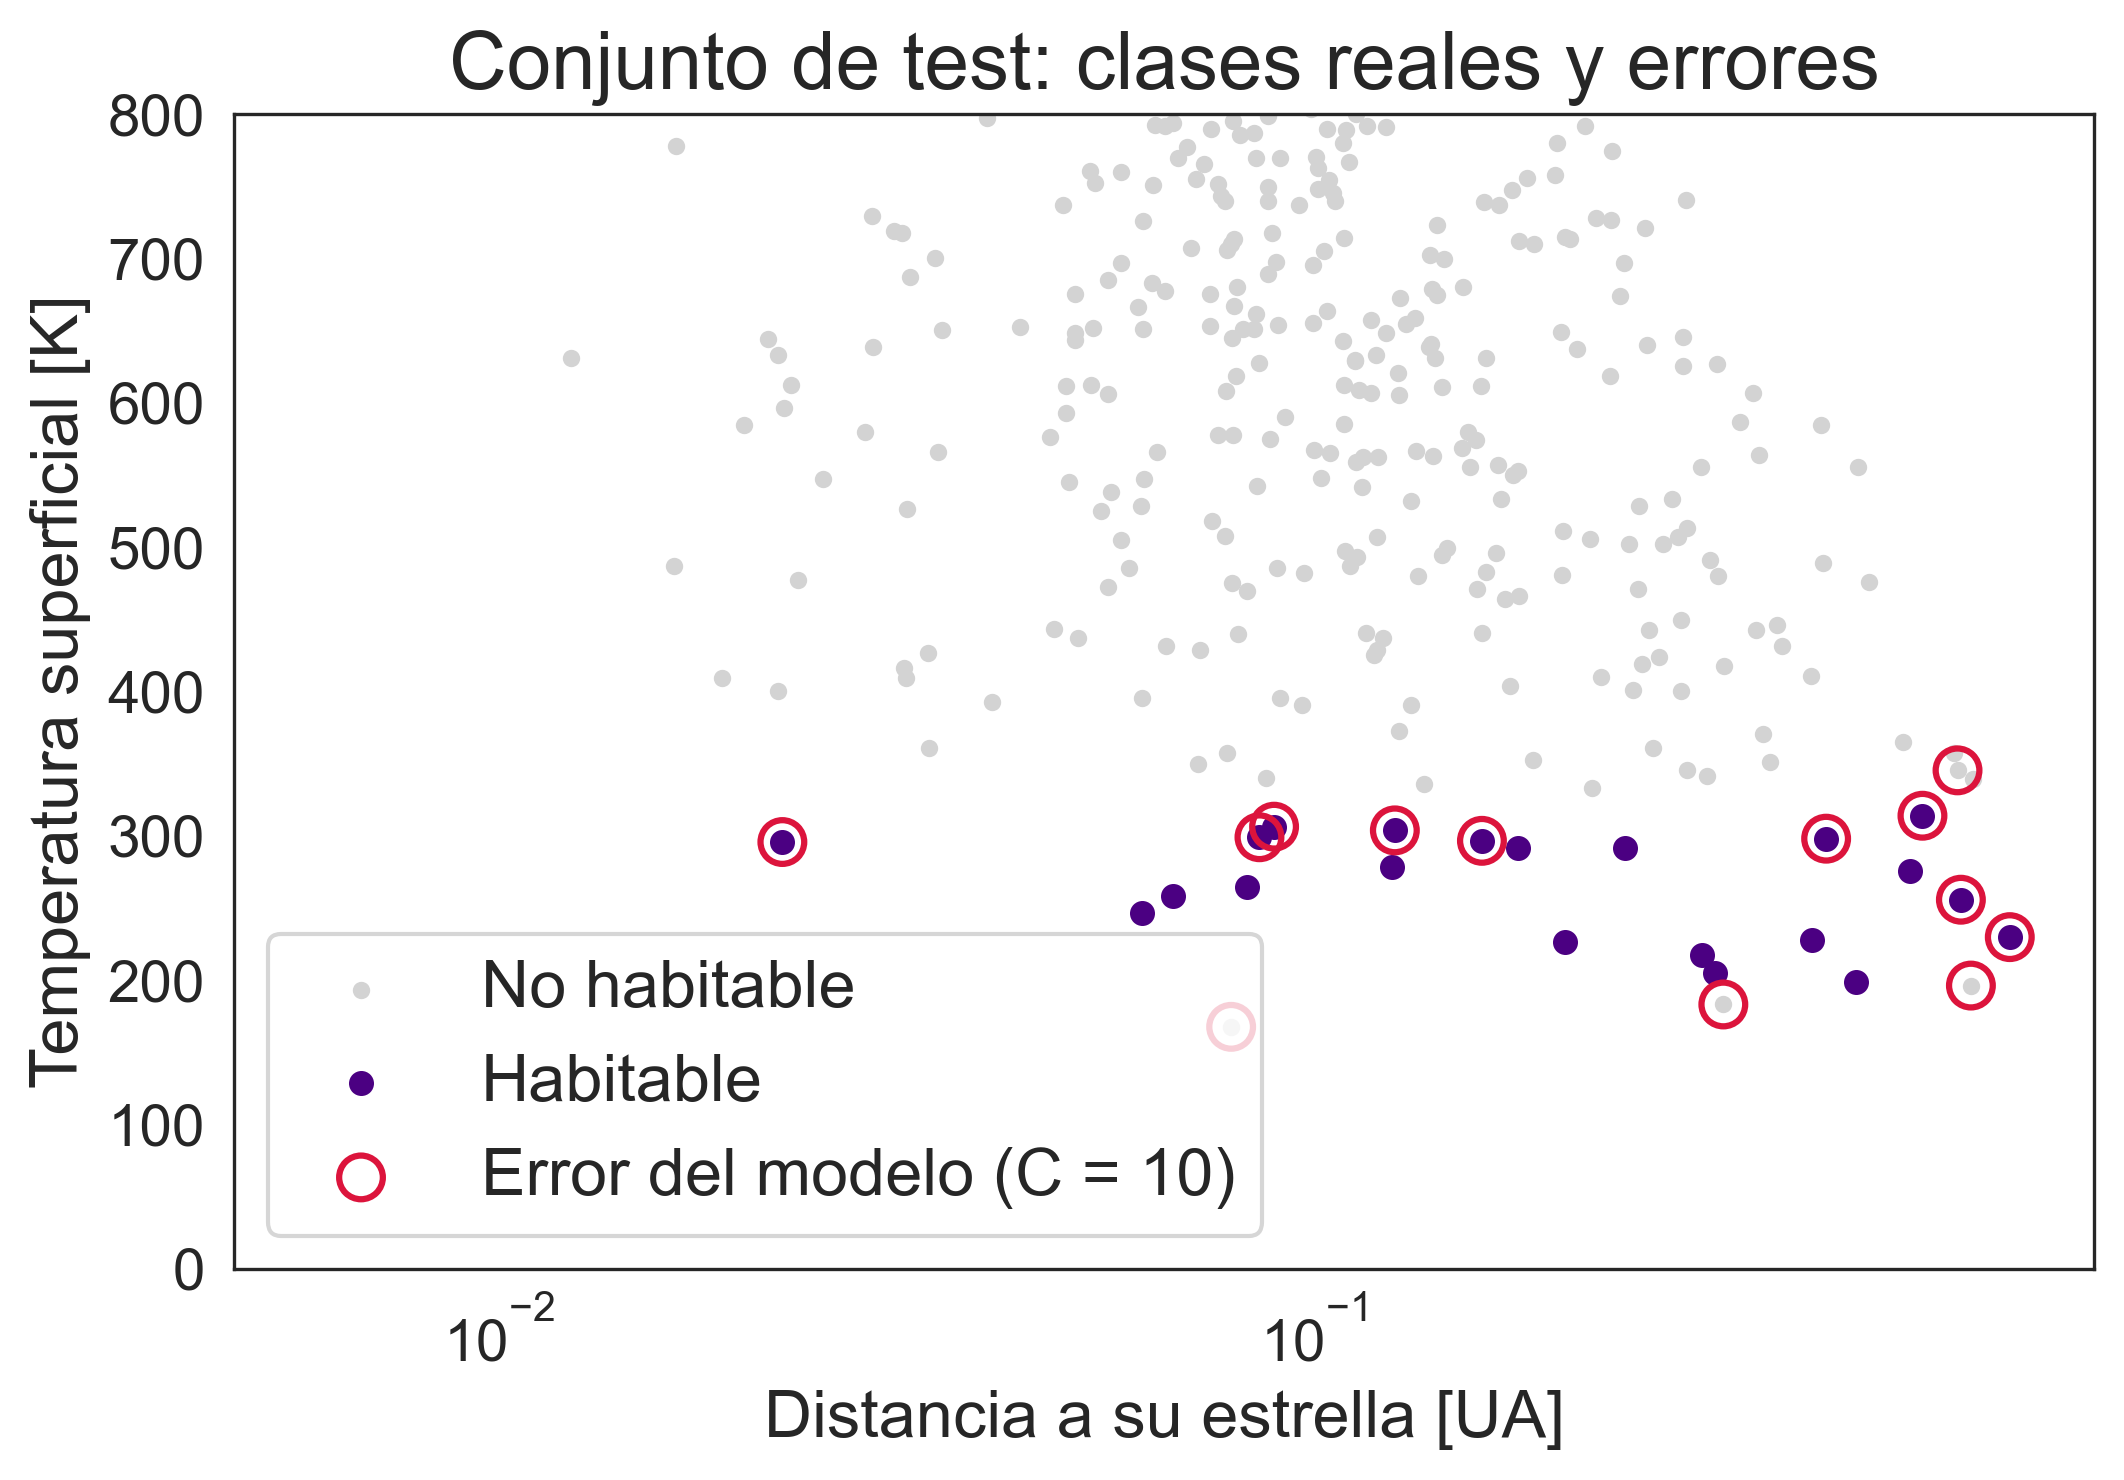

Rango de temperatura de los habitables: 199-325 K
Dentro de ese rango hay 78 exoplanetas, de los cuales 70 están en zonas potencialmente habitables

Con C = 1000 hay 8 errores, los 8 ya eran errores con C = 10


In [15]:
fig, ax = plt.subplots(figsize=(8, 5))
Xt = df.loc[X_test.index]
ax.scatter(Xt.loc[y_test == 0, "P_DISTANCE"], Xt.loc[y_test == 0, "P_TEMP_SURF"],
           s=10, color="lightgrey", label="No habitable")
ax.scatter(Xt.loc[y_test == 1, "P_DISTANCE"], Xt.loc[y_test == 1, "P_TEMP_SURF"],
           s=25, color="indigo", label="Habitable")
ax.scatter(errores["P_DISTANCE"], errores["P_TEMP_SURF"], s=110, facecolors="none",
           edgecolors="crimson", linewidths=1.5, label="Error del modelo (C = 10)")
ax.set_xscale("log")
ax.set_ylim(0, 800)
ax.set_xlabel("Distancia a su estrella [UA]")
ax.set_ylabel("Temperatura superficial [K]")
ax.set_title("Conjunto de test: clases reales y errores")
ax.legend()
plt.show()

hab = df[df[target] == 1]
tmin, tmax = hab["P_TEMP_SURF"].min(), hab["P_TEMP_SURF"].max()
ventana = df[df["P_TEMP_SURF"].between(tmin, tmax)]
print(f"Rango de temperatura de los habitables: {tmin:.0f}-{tmax:.0f} K")
print(f"Dentro de ese rango hay {len(ventana)} exoplanetas, de los cuales {int(ventana[target].sum())} están en zonas potencialmente habitables")

pred_1000 = crear_modelo(1000).fit(X_train, y_train).predict(X_test)
mask_1000 = pred_1000 != y_test.values
persisten = len(set(X_test.index[mask_1000]) & set(errores.index))
print(f"\nCon C = 1000 hay {int(mask_1000.sum())} errores, los {persisten} ya eran errores con C = 10")

In [18]:
# ¿Falla más en alguna zona? Cortes no arbitrarios: punto medio del rango de temperatura de los habitables
# y mediana de su distancia (así cada corte reparte los habitables en dos mitades)
tmid = (tmin + tmax) / 2
dmed = hab["P_DISTANCE"].median()
print(f"Corte de temperatura: {tmid:.0f} K | corte de distancia (mediana de los que están en zonas potencialmente habitables habitables): {dmed:.3f} UA\n")

Xt = df.loc[X_test.index]
grupos = {
    f"T < {tmid:.0f} K": (Xt["P_TEMP_SURF"] < tmid).values,
    f"T >= {tmid:.0f} K": (Xt["P_TEMP_SURF"] >= tmid).values,
    f"dist < {dmed:.3f} UA": (Xt["P_DISTANCE"] < dmed).values,
    f"dist >= {dmed:.3f} UA": (Xt["P_DISTANCE"] >= dmed).values,
}
filas = []
for nombre, g in grupos.items():
    pos_g = (y_test.values == 1) & g
    filas.append({"grupo": nombre, "habitables en test": int(pos_g.sum()),
                  "detectados con C=10": f"{int(((pred == 1) & pos_g).sum())}/{int(pos_g.sum())}",
                  "detectados con C=1000": f"{int(((pred_1000 == 1) & pos_g).sum())}/{int(pos_g.sum())}"})
display(pd.DataFrame(filas))

print("\nMezcla de clases dentro del rango de temperatura de los habitables (todos los datos, descriptivo):")
for nombre, sub in [("mitad baja", ventana[ventana["P_TEMP_SURF"] < tmid]),
                    ("mitad alta", ventana[ventana["P_TEMP_SURF"] >= tmid])]:
    print(f"  {nombre}: {int(sub[target].sum())} en zonas potencialmente habitables y {int((sub[target] == 0).sum())} no potencialmente habitables")

Corte de temperatura: 262 K | corte de distancia (mediana de los que están en zonas potencialmente habitables habitables): 0.165 UA



,grupo,habitables en test,detectados con C=10,detectados con C=1000
0,T < 262 K,9,7/9,8/9
1,T >= 262 K,12,5/12,8/12
2,dist < 0.165 UA,9,4/9,7/9
3,dist >= 0.165 UA,12,8/12,9/12



Mezcla de clases dentro del rango de temperatura de los habitables (todos los datos, descriptivo):
  mitad baja: 28 en zonas potencialmente habitables y 1 no potencialmente habitables
  mitad alta: 42 en zonas potencialmente habitables y 7 no potencialmente habitables


**Patrones en los errores.**

- **Falsos positivos (4):** tienen temperaturas de 168, 183, 196 y 345 K, es decir, quedan justo fuera del rango de los
  habitables (199-325 K), a 31 K o menos de sus bordes. El modelo "se pasa" un poco del borde de la ventana.
- **Falsos negativos (9):** 7 de 9 tienen temperaturas entre 295 y 314 K, en la **mitad alta** de la ventana. La tabla
  lo confirma con ambos valores de `C`: en la mitad alta (T ≥ 262 K) se detectan 5 de 12 habitables con `C = 10` y
  8 de 12 con `C = 1000`, contra 7 de 9 y 8 de 9 en la mitad baja. Y en la mitad alta las clases se mezclan más:
  hay 42 habitables y 7 no habitables, contra 28 y 1 en la mitad baja.
- Al observar que 5 de los 9 falsos negativos están muy cerca de su estrella (menos de 0.17 UA),
  por ejemplo TRAPPIST-1 d (0.022 UA), no sería posible generalizar. La mitad de los habitables de esta muestra son así de
  cercanos (distancia mediana de 0.165 UA), y el recall en esos casos cambia con `C` (4 de 9 con `C = 10` contra 7 de 9
  con `C = 1000`, mientras que para los más lejanos es 8 de 12 y 9 de 12). Con tan pocos casos no podemos afirmar que la
  distancia sea una causa de error.
- Se podría decir que en la mitad alta de la ventana la temperatura sola no separa bien las clases, y dos planetas con
  temperaturas parecidas pueden notablemente tener etiquetas distintas. Si el catálogo define la zona habitable a partir de la
  energía que emite la estrella por ejemplo (algo que el modelo no ve), una variable de la estrella podría ayudar. Para evaluarla y tratar de mejorar aún más el modelo, sería
  agregar la luminosidad o temperatura de la estrella anfitriona.
- Considerando los 8 errores del modelo con `C = 1000` ya eran errores con `C = 10`: un `C`
  más alto corrige los casos simples, pero no los que están realmente en el borde o fuera del alcance de las features.

<h2 style="color:lightblue; font-family:; text-align:left;font-size:17px">
 ¿Qué aprendimos que no era evidente a partir de una única métrica global?
</h2>

1. Del accuracy no es posible generalizar del todo si es que es alta, dado que va de 97.1% a 99%, y además se ha mejorado considerablemente F1, siendo este al principio F1 = 0 y luego F1 = 0.65-0.80 que era lo que se buscaba.
2. En el rango de temperatura de los habitables hay 78 exoplanetas, 70
   habitables y solo 8 no habitables (90%). El SVM está esencialmente aprendiendo ese rango, y sus errores se acumulan
   en los bordes, sobre todo en el superior.
3. La dificultad con planetas cercanos aparecía con
   `C = 10` y casi desaparecía con `C = 1000`; en cambio, la dificultad en la mitad alta de la temperatura se mantuvo.
   Con una sola métrica global, o un solo valor de `C`, no habríamos podido distinguir entre ambos.
4. El modelo se evalúa solo sobre exoplanetas con temperatura, y
   el procedimiento descartó la mayoría de los habitables (los detectados por velocidad radial). Una métrica alta en
   este test no dice nada sobre esos planetas.

<h2 style="color:lightblue; font-family:; text-align:left;font-size:17px">
 ¿Cómo mejorarían el modelo?
</h2>

**Propuesta: agregar una variable de la estrella anfitriona (por ejemplo `S_LUMINOSITY`) como feature.** Se justifica
con los resultados: (1) como muestra la celda siguiente, esa variable existe para todos los habitables, lo que permitiría
probar un modelo que no dependa de `P_TEMP_SURF` y así poder tener los 194 en zona potencialmente habitables, reduciendo el
sesgo de selección debido a que las clases estaban desbalanceadas y aumentando los positivos para entrenar y evaluar (hoy solo 70, de los cuales 21 en test); (2) los
errores se concentran en la mitad alta del rango de temperatura, donde las clases se mezclan y la temperatura sola no
alcanza, así que información sobre la estrella es un candidato razonable para separarlas (hipótesis a evaluar).

Como la zona potencial habitable se define a partir de la luminosidad estelar y la distancia orbital, con esta
variable el modelo podría terminar reproduciendo la definición del catálogo en vez de "predecir" algo nuevo. Aunque habría que ver si surge alguna otra información relevante con que se pueda seguir.

También se podría usar `class_weight="balanced"` en el SVM.Con solo ~3% de habitables, el modelo original
(`C = 1`) no tomó en cuenta la clase minoritaria (F1 = 0), y solo con un `C` alto empezó a detectarla: con `C = 10`
el recall es de 0.57, es decir, se escapan 9 de los 21 habitables del test. Ponderar más los errores sobre los
habitables obligaría al modelo a tomarlos en cuenta sin depender de un `C` tan alto. Esperamos más recall (detectar más
habitables) a costa de menos precision (más falsos positivos); no lo implementamos, como pide el enunciado.

In [19]:
print("Habitables sin S_LUMINOSITY:", int(EXO_set.loc[EXO_set[target] == 1, "S_LUMINOSITY"].isna().sum()), "de", n_pos_total)

Habitables sin S_LUMINOSITY: 0 de 264


<h2 style="color:fuchsia; font-family:; text-align:center;font-size:23px">
  (7) ❁ Conclusiones ❁
</h2>
**¿Qué tan confiable es el modelo?** Poco confiable para este problema, aunque útil como ejercicio para entender las limitaciones por desbalanceo de clases.

- Se tiene un buen resultado con `C` ≥ 10, el SVM detecta entre 57% y 76% de los habitables del test con una precision de 71% a
  84%, mientras que el modelo original no detecta ninguno. Además sus errores son interpretables se concentran en
  los bordes del rango de temperatura que habíamos identificado en la Tarea 1.
- Aunque igual hay distintas limitaciones como; solo hay 70 habitables y 21 en el test, por lo que las métricas son inestables y no permiten
  decidir qué `C` es mejor y la muestra de entrenamiento excluye al 74% de los habitables por faltarles temperatura
  (debido a que se detectan por velocidad radial), así que los resultados no se pueden extrapolar a toda la población. Además el modelo no conoce la estrella, y sus errores se concentran en la mitad alta del rango de temperatura, donde las clases se mezclan.

Un accuracy cercano al 99% no implica que el modelo sea adecuado. Además, `P_HABZONE_OPT` es una etiqueta del catálogo y no una medida de habitabilidad real, para la cual faltan atmósfera, agua líquida, etc.

<h2 style="color:fuchsia; font-family:; text-align:center;font-size:23px">
  (8) ❁ Uso de herramientas de IA ❁
</h2>

Para resolver dudas de como utilizar algunos comandos se utilizó Claude, en conjunto con el libro de ML y actividades anteriores con conceptos específicos.